# Собери команду: классы и наследование

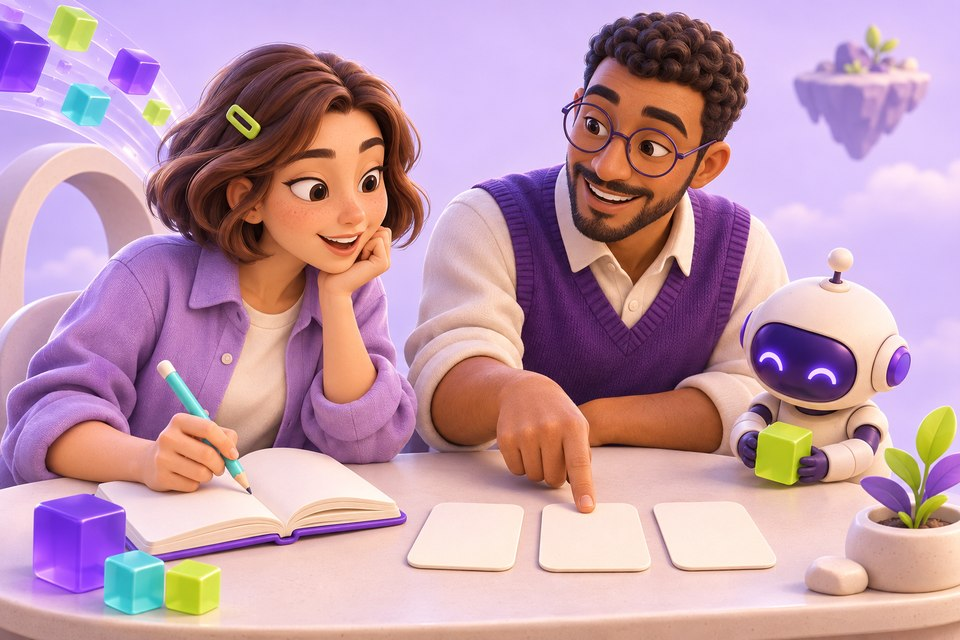

**Создаём ученика и ментора, которые используют общий код.**

**Твой результат:** Сделать два объекта с общими данными и разным поведением без ошибки super.

**Что разбираем:** Основы ООП на понятных персонажах. Продвинутый VAE с собственным train_step остаётся в архиве и здесь не обучается.

**Данные:** Вымышленные персонажи Мира и Данил; данные заданы прямо в коде.

**Перед началом:**

- Уметь запускать ячейки по порядку
- Знать переменные и списки Python

**Рядом с тобой:** Мира — ученица, Данил — человек-ментор, Пикс — бот-помощник. Это вымышленные персонажи: их реплики объясняют шаги и не проверяют код автоматически.

## Три шага

1. Создай общий портрет участника
2. Добавь ученику и ментору свои роли
3. Обратись к разным объектам одинаково

Затем — твой небольшой эксперимент. Проходи ячейки сверху вниз.

## Подготовь рабочее место

Запускай код сверху вниз: сначала эту подготовку, затем три шага. Проверки `assert` останавливают выполнение, если результат не совпал с условием.

Библиотеки для урока: **только стандартный Python**.

In [1]:
print('Рабочее место готово: используем встроенный Python.')


Рабочее место готово: используем встроенный Python.


<a id="step-1"></a>

## 1. Создай общий портрет участника

Класс хранит данные и поведение вместе. Конструктор сразу задаёт имя, поэтому объект готов к работе после создания.

In [2]:
class Person:
    def __init__(self, name):
        if not name.strip():
            raise ValueError('Имя не должно быть пустым')
        self.name = name

    def about(self):
        return f'Меня зовут {self.name}'

person = Person('Мира')
assert person.about() == 'Меня зовут Мира'
print(person.about())


Меня зовут Мира


**Что проверить:** Объект сразу умеет представиться, без отдельного вызова для установки имени.

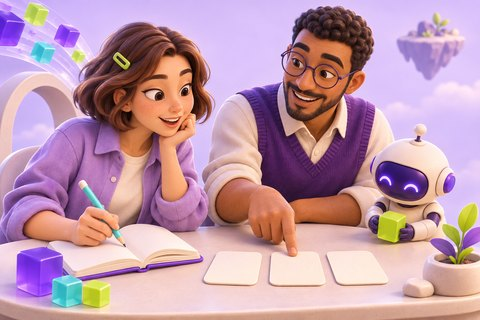

> **Мира:** Можно сначала создать пустого человека, а имя дать позже?

> **Данил:** Можно спроектировать и так, но легко забыть второй шаг. Здесь обязательное имя задаётся при создании.

> **Пикс:** Вызови Person с пустой строкой отдельно и прочитай понятную ошибку.

<a id="step-2"></a>

## 2. Добавь ученику и ментору свои роли

Дочерние классы повторно используют конструктор и представление родителя. super() обращается к правильному родителю без имени чужого класса.

In [3]:
class Learner(Person):
    def __init__(self, name, project):
        super().__init__(name)
        self.project = project

    def about(self):
        return super().about() + f'. Мой проект: {self.project}'

class Mentor(Person):
    def about(self):
        return super().about() + '. Помогаю проверить следующий шаг'

mira = Learner('Мира', 'игра с ботом')
danil = Mentor('Данил')
assert isinstance(mira, Person) and isinstance(danil, Person)
assert 'игра с ботом' in mira.about()
print(mira.about())
print(danil.about())


Меня зовут Мира. Мой проект: игра с ботом
Меня зовут Данил. Помогаю проверить следующий шаг


**Что проверить:** Оба персонажа используют общее представление и добавляют свою часть.

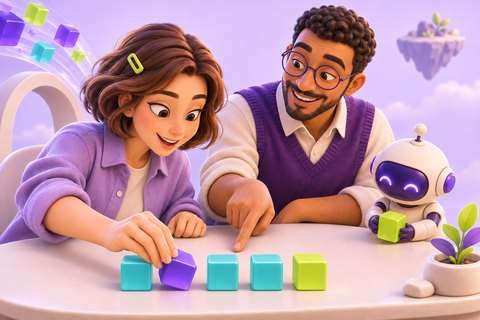

> **Мира:** Нужно ли писать имя родительского класса в super?

> **Данил:** В этих обычных методах достаточно super(). Это убирает ошибку копирования чужого имени класса.

> **Пикс:** Оба вызова about должны пройти без NameError и TypeError.

<a id="step-3"></a>

## 3. Обратись к разным объектам одинаково

Один и тот же вызов about() работает для разных ролей. Изменение проекта Миры не должно менять данные другого ученика.

In [4]:
second_learner = Learner('Лев', 'таблица результатов')
mira.project = 'новая игра'
team = [mira, danil, second_learner]
messages = [member.about() for member in team]
assert len(messages) == len(team)
assert second_learner.project == 'таблица результатов'
assert 'новая игра' in messages[0]
for message in messages:
    print(message)


Меня зовут Мира. Мой проект: новая игра
Меня зовут Данил. Помогаю проверить следующий шаг
Меня зовут Лев. Мой проект: таблица результатов


**Что проверить:** Каждый отвечает по своей роли, а проекты двух учеников независимы.

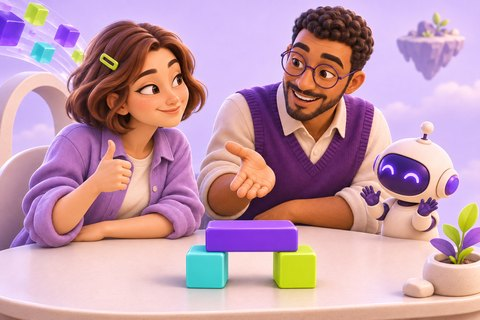

> **Мира:** Как цикл понимает, кого попросили представиться?

> **Данил:** Он вызывает метод объекта. Реализация выбирается по его классу — это полиморфизм.

> **Пикс:** После изменения Миры проверь проект Льва: он должен сохраниться.

<a id="your-experiment"></a>

## Попробуй сам

Добавь класс Designer с собственным about().

**Где изменить:** Наследуй Person, дополни результат super().about() и добавь Designer в конец списка team.

**Как проверить:** Новый объект можно добавить в team, не меняя цикл печати.

## Что теперь умеешь

- Конструктор создаёт готовый объект.
- super() повторно использует поведение родителя.
- Разные классы могут поддерживать один интерфейс.

## Границы этого примера

- Персонажи вымышлены и не являются отзывами реальных учеников.
- VAE, нейросетевое обучение и скрытое пространство остаются продвинутым продолжением в архиве.

## Продолжить глубже

[Полная исходная работа в неизменяемом архиве](<https://github.com/safal207/students/blob/2e46691c24aabcb6e71852e07254a0965fc3a59b/OOP/%D0%94%D0%BE%D0%BF%D0%BE%D0%BB%D0%BD%D0%B8%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D1%8B%D0%B9_%D1%81%D0%B5%D0%BC%D0%B8%D0%BD%D0%B0%D1%80_%D0%9E%D0%9E%D0%9F.ipynb>). Она сохраняет большой эксперимент и его авторские материалы; её требования могут отличаться от этого короткого урока.

**Источники исходной работы:**

- [Источник 1](<https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%94%D0%BE%D0%BF%D0%BE%D0%BB%D0%BD%D0%B8%D1%82%D0%B5%D0%BB%D1%8C%D0%BD%D1%8B%D0%B9_%D1%81%D0%B5%D0%BC%D0%B8%D0%BD%D0%B0%D1%80_%D0%9E%D0%9E%D0%9F.ipynb>)

<details>
<summary>Что исправлено и упрощено в уроке</summary>

**Ошибка · исходная ячейка 30 (от 0).** Метод первого дочернего класса вызывает super с именем другого класса. → В дочернем методе используется super().about().

Проверка: Создание Learner и вызов about успешно выполняются.

Фрагмент исходника: <code>super(childThree, self).about_me() внутри childOne</code>

---

**Ошибка · исходная ячейка 34 (от 0).** Та же ошибка скопирована во второй дочерний класс. → Каждый класс обращается к своему родителю через super().

Проверка: Создание Mentor и вызов about успешно выполняются.

Фрагмент исходника: <code>super(childThree, self).about_me() внутри childTwo</code>

</details>